# Predicting Pharmaceutical Production Yield Using Machine Learning
### A Comparative Study of Regression and Regularization Techniques
*CS 5821 Machine Learning — course project notebook*

**Research question.** How accurately can pharmaceutical production yield be predicted from historical
manufacturing measurements, and which machine-learning method offers the best balance between
prediction accuracy, complexity and interpretability?

**Hypothesis.** With 57 correlated predictors and only 176 batches, an ordinary least-squares model
will overfit. Methods that control model complexity (Ridge, Lasso, PCR) should generalise better
than OLS, and a sparse model (Lasso) should give the best accuracy-interpretability trade-off.

> **Scope.** This is a retrospective statistical analysis of a public teaching dataset. Associations
> found here are *predictive, not causal*, and nothing in this notebook is a recommendation for
> changing real manufacturing settings.

**Notebook outline** (same order as the report)
1. Data and setup
2. Exploratory data analysis
3. Batch dependency check
4. Preprocessing and leakage control
5. Models: OLS, Ridge, Lasso, PCR, KNN
6. Model evaluation and comparison
7. Sensitivity analyses (batch-grouped validation, repeated splits)
8. Findings, conclusions, limitations and references

## 1. Data and setup

**Dataset.** `ChemicalManufacturingProcess` from the R package *AppliedPredictiveModeling*
(Kuhn & Johnson, 2013). Each row is one manufacturing batch of a pharmaceutical product:

* `Yield` – percentage yield of the batch (the target);
* `BiologicalMaterial01–12` – measurements of the raw biological material (cannot be changed by the process);
* `ManufacturingProcess01–45` – measurements taken during the manufacturing process.

All project code lives in `src/`; the notebook calls those functions so the scripts and the
notebook always produce identical numbers.

In [1]:
import sys, warnings
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import data_loader as dl, preprocessing as pp, train_models as tm
from src import evaluate_models as ev, visualizations as viz

%matplotlib inline
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
viz.set_style()

def show(fig):
    display(fig)
    plt.close(fig)

In [2]:
df = dl.load_data()          # reads data/ChemicalManufacturingProcess.csv (downloads it if absent)
print("Shape:", df.shape)
print("Column types:", df.dtypes.value_counts().to_dict())
display(dl.dataset_overview(df).T.rename(columns={0: "value"}))
df.head()

Shape: (176, 58)
Column types: {dtype('float64'): 51, dtype('int64'): 7}


,value
observations,176
predictors,57
biological_material,12
manufacturing_process,45
missing_cells,106
columns_with_missing,28
rows_with_missing,24
distinct_bio_profiles,108
rows_in_shared_profiles,103


,Yield,BiologicalMaterial01,BiologicalMaterial02,BiologicalMaterial03,BiologicalMaterial04,BiologicalMaterial05,BiologicalMaterial06,BiologicalMaterial07,BiologicalMaterial08,BiologicalMaterial09,BiologicalMaterial10,BiologicalMaterial11,BiologicalMaterial12,ManufacturingProcess01,ManufacturingProcess02,...,ManufacturingProcess31,ManufacturingProcess32,ManufacturingProcess33,ManufacturingProcess34,ManufacturingProcess35,ManufacturingProcess36,ManufacturingProcess37,ManufacturingProcess38,ManufacturingProcess39,ManufacturingProcess40,ManufacturingProcess41,ManufacturingProcess42,ManufacturingProcess43,ManufacturingProcess44,ManufacturingProcess45
0,38.00,6.25,49.58,56.97,12.74,19.51,43.73,100.0,16.66,11.44,3.46,138.09,18.83,NaN,NaN,...,69.1,156,66.0,2.4,486.0,0.019,0.5,3,7.2,NaN,NaN,11.6,3.0,1.8,2.4
1,42.44,8.01,60.97,67.48,14.65,19.36,53.14,100.0,19.04,12.55,3.46,153.67,21.05,0.0,0.0,...,68.7,169,66.0,2.6,508.0,0.019,2.0,2,7.2,0.1,0.15,11.1,0.9,1.9,2.2
2,42.03,8.01,60.97,67.48,14.65,19.36,53.14,100.0,19.04,12.55,3.46,153.67,21.05,0.0,0.0,...,69.3,173,66.0,2.6,509.0,0.018,0.7,2,7.2,0.0,0.00,12.0,1.0,1.8,2.3
3,41.42,8.01,60.97,67.48,14.65,19.36,53.14,100.0,19.04,12.55,3.46,153.67,21.05,0.0,0.0,...,69.3,171,68.0,2.5,496.0,0.018,1.2,2,7.2,0.0,0.00,10.6,1.1,1.8,2.1
4,42.49,7.47,63.33,72.25,14.02,17.91,54.66,100.0,18.22,12.80,3.05,147.61,21.05,10.7,0.0,...,69.4,171,70.0,2.5,468.0,0.017,0.2,2,7.3,0.0,0.00,11.0,1.1,1.7,2.1


The download matches the documented dataset: **176 batches, 57 predictors (12 biological + 45 process)
and the target `Yield`**. All columns are numeric. 106 cells are missing, spread over 28 predictors
and 24 batches; the target itself is complete.

## 2. Exploratory data analysis
### 2.1 Summary statistics

In [3]:
summary = df.describe().T
summary["missing"] = df.isna().sum()
summary.loc[["Yield"] + list(df.columns[1:6]) + list(df.columns[13:18])]

,count,mean,std,min,25%,50%,75%,max,missing
Yield,176.0,40.177,1.846,35.25,38.752,39.970,41.475,46.34,0
BiologicalMaterial01,176.0,6.411,0.714,4.58,5.978,6.305,6.870,8.81,0
BiologicalMaterial02,176.0,55.689,4.035,46.87,52.680,55.090,58.737,64.75,0
BiologicalMaterial03,176.0,67.705,4.001,56.97,64.980,67.220,70.428,78.25,0
BiologicalMaterial04,176.0,12.349,1.775,9.38,11.245,12.100,13.220,23.09,0
BiologicalMaterial05,176.0,18.599,1.844,13.24,17.235,18.490,19.900,24.85,0
ManufacturingProcess01,175.0,11.207,1.822,0.00,10.800,11.400,12.150,14.10,1
ManufacturingProcess02,173.0,16.683,8.472,0.00,19.300,21.000,21.500,22.50,3
ManufacturingProcess03,161.0,1.540,0.022,1.47,1.530,1.540,1.550,1.60,15
ManufacturingProcess04,175.0,931.851,6.274,911.00,928.000,934.000,936.000,946.00,1


The predictors are on very different scales (some are around 0.1, others in the thousands), so any
method based on distances or penalties (Ridge, Lasso, PCA, KNN) needs **standardised** inputs.

### 2.2 Missing values

,missing,percent
ManufacturingProcess03,15,8.523
ManufacturingProcess11,10,5.682
ManufacturingProcess10,9,5.114
ManufacturingProcess33,5,2.841
ManufacturingProcess26,5,2.841
ManufacturingProcess25,5,2.841
ManufacturingProcess29,5,2.841
ManufacturingProcess30,5,2.841
ManufacturingProcess31,5,2.841
ManufacturingProcess27,5,2.841


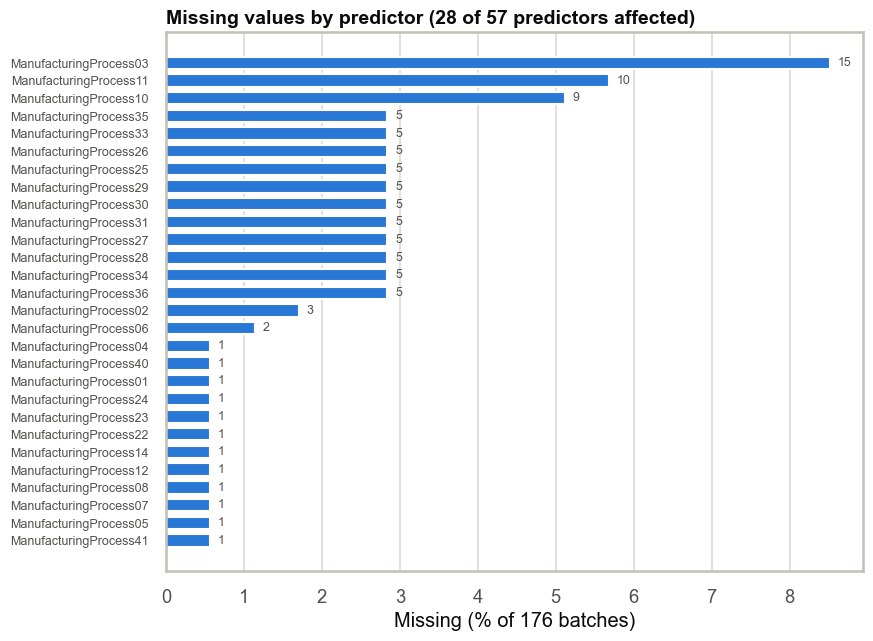

In [4]:
missing = pp.missing_summary(df)
display(missing.head(10))
show(viz.plot_missing_values(missing))

At most 8.5 % of any column is missing (`ManufacturingProcess03`, 15 of 176), and most affected
columns miss only 1–5 values. This is small enough for **median imputation** to be a reasonable,
simple choice. The median is robust to the outliers we find below. Several process columns are
missing for the *same* five batches, which suggests a measurement step that was skipped for those batches.

### 2.3 Target variable: production yield

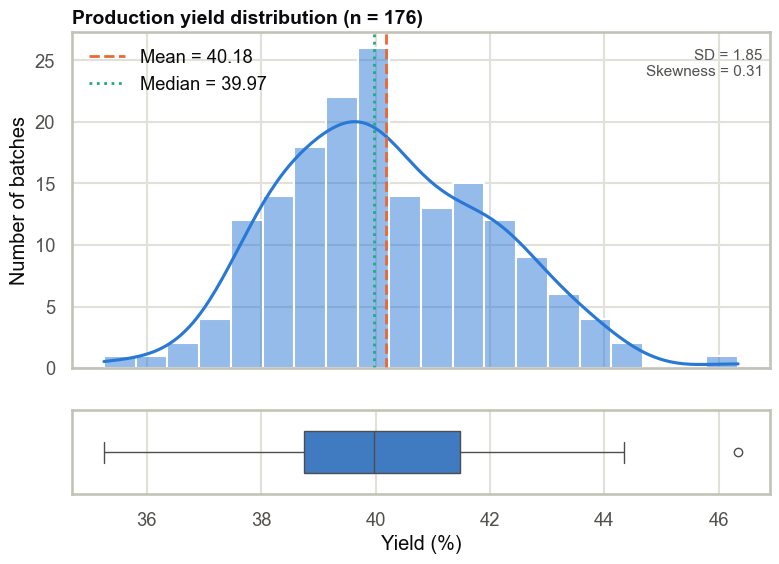

In [5]:
y_all = df[dl.TARGET]
show(viz.plot_yield_distribution(y_all))

Yield ranges from about 35.3 % to 46.3 %, with mean 40.2 % and standard deviation 1.85. The
distribution is roughly bell-shaped with a slight right skew (a few unusually high-yield batches).
**The standard deviation of 1.85 is the key benchmark.** Always predicting the mean would give an
RMSE of about 1.85, so a useful model must do clearly better than that.

### 2.4 Train/test split (made *before* the remaining EDA)

From here on, anything that could influence modelling decisions (correlations, feature subsets)
is computed on the **training set only**, so the test set stays untouched.

In [6]:
X, y = dl.split_xy(df)
X_train, X_test, y_train, y_test = pp.make_train_test_split(X, y)   # 80/20, random_state=42
print(f"Training: {X_train.shape}, Test: {X_test.shape}")
print(f"Mean yield train = {y_train.mean():.2f}, test = {y_test.mean():.2f}")

Training: (140, 57), Test: (36, 57)
Mean yield train = 40.06, test = 40.62


### 2.5 Predictor distributions

,r with Yield
ManufacturingProcess32,0.597
BiologicalMaterial06,0.538
ManufacturingProcess36,-0.534
BiologicalMaterial02,0.516
ManufacturingProcess13,-0.511
ManufacturingProcess09,0.498
BiologicalMaterial03,0.484
ManufacturingProcess17,-0.468
ManufacturingProcess33,0.432
BiologicalMaterial12,0.423


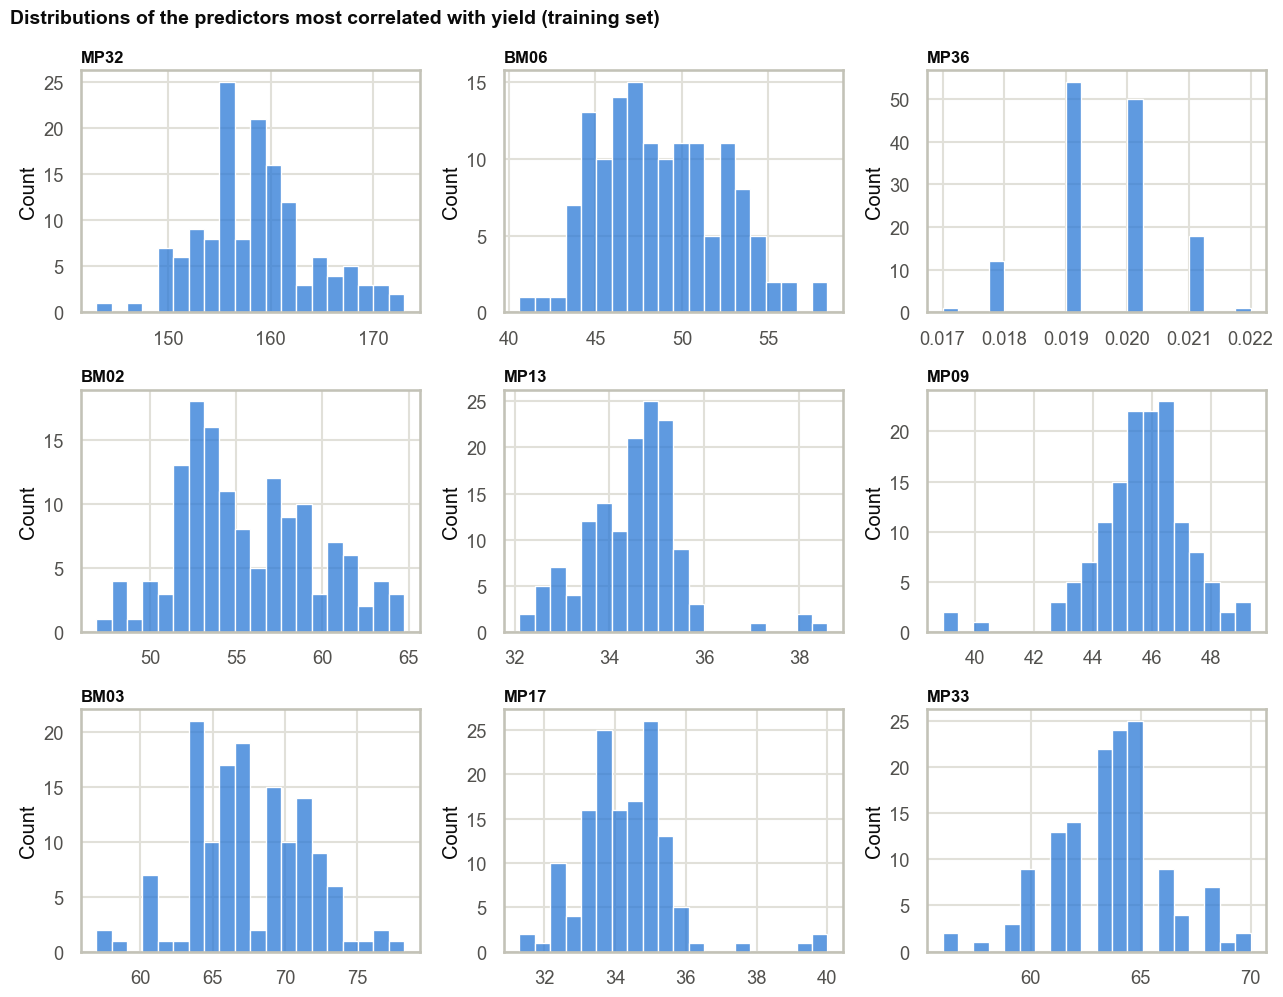

In [7]:
target_corr = pp.target_correlations(X_train, y_train)
top12 = list(target_corr.index[:12])
display(target_corr.head(12).rename("r with Yield").to_frame())
show(viz.plot_predictor_histograms(X_train, top12[:9]))

The predictors most correlated with yield are a mix of process variables (MP32, MP36, MP13, MP09, MP17)
and biological variables (BM06, BM02, BM03). Several of these histograms are skewed or show
isolated extreme values (for example MP13 and MP17), so we look at outliers next.

### 2.6 Outlier exploration

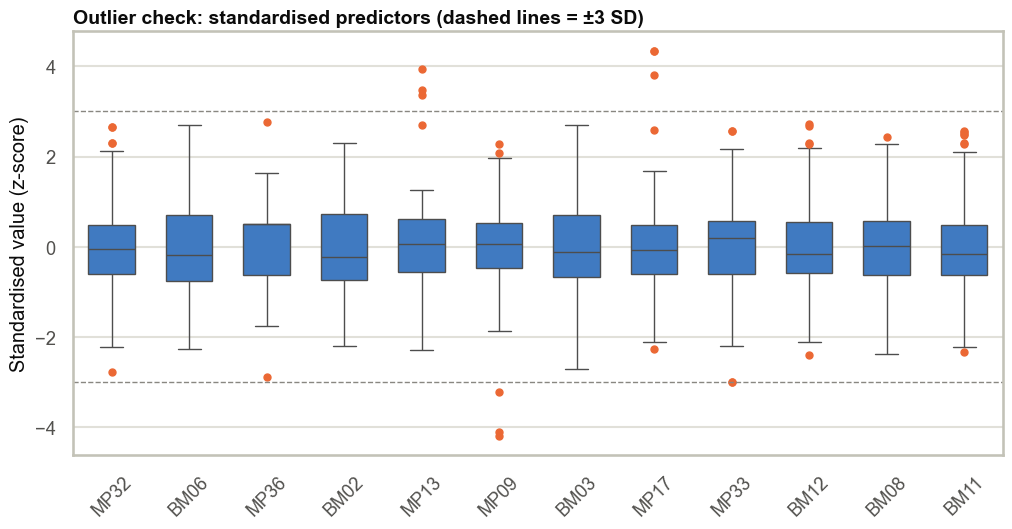

,max |z|,column
21,11.753,ManufacturingProcess18
22,11.678,ManufacturingProcess16
107,11.613,ManufacturingProcess26
58,10.681,ManufacturingProcess43
46,7.305,ManufacturingProcess06


In [8]:
show(viz.plot_predictor_boxplots(X_train, top12))
z = (X_train - X_train.median()) / X_train.std()
extreme = z.abs().max(axis=1).sort_values(ascending=False).head(5)
pd.DataFrame({"max |z|": extreme, "column": z.abs().idxmax(axis=1)[extreme.index]})

Most predictors stay within ±3 SD. A handful of batches, however, are **more than 10 standard
deviations** from the median on one process variable. These rows have a value of exactly 0 in columns
such as `ManufacturingProcess16/18/26/43`, where every other batch is in the hundreds or thousands.
These zeros look like recording artefacts, but we have no documentation to confirm it, so we
**keep them unchanged** and note them as a limitation. As Section 5 shows, they matter: unregularised
linear models extrapolate wildly when such a batch falls in a validation fold.

### 2.7 Correlation structure and multicollinearity

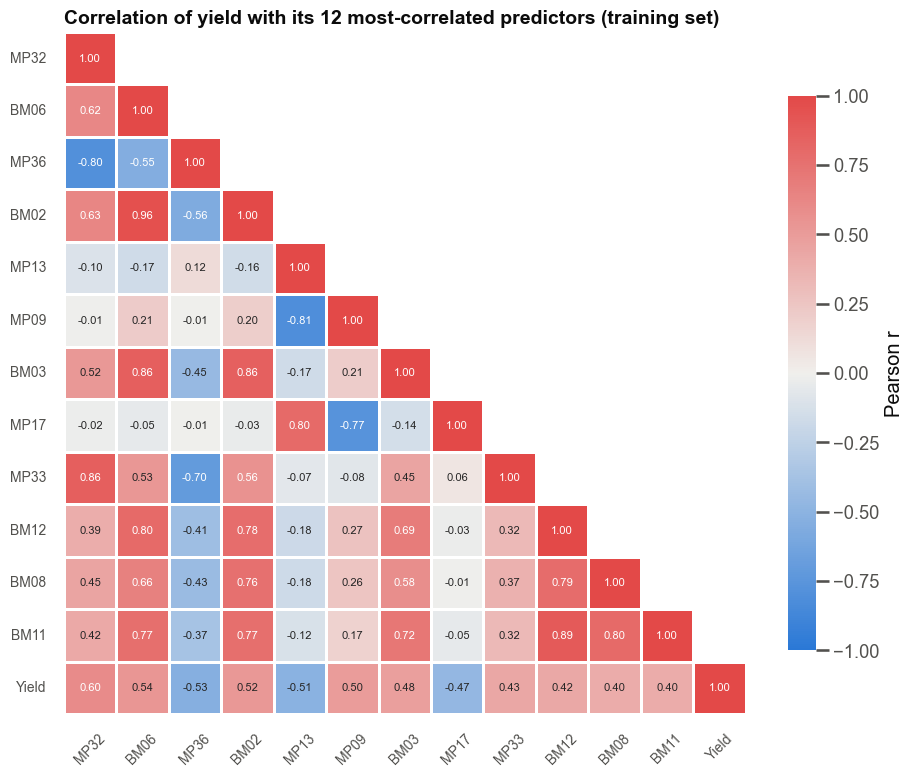

In [9]:
show(viz.plot_correlation_heatmap(X_train, y_train, top12))

**Reading the heatmap.** The bottom row shows each predictor's correlation with yield (|r| between
0.40 and 0.60). No single variable explains most of the variation, so we need a multivariable model.
The rest of the triangle shows strong correlations *between* predictors: BM02–BM06 r = 0.96,
MP32–MP33 r = 0.86, MP13–MP09 r = −0.81. Correlated predictors carry overlapping information.

14 predictor pairs have |r| >= 0.90 in the training set


,feature_1,feature_2,r
0,ManufacturingProcess25,ManufacturingProcess26,0.998
1,ManufacturingProcess26,ManufacturingProcess27,0.997
2,ManufacturingProcess25,ManufacturingProcess27,0.995
3,ManufacturingProcess18,ManufacturingProcess20,0.994
4,ManufacturingProcess25,ManufacturingProcess31,0.976
5,ManufacturingProcess26,ManufacturingProcess31,0.968
6,ManufacturingProcess27,ManufacturingProcess31,0.963
7,ManufacturingProcess26,ManufacturingProcess29,0.963
8,ManufacturingProcess27,ManufacturingProcess29,0.962
9,BiologicalMaterial02,BiologicalMaterial06,0.957


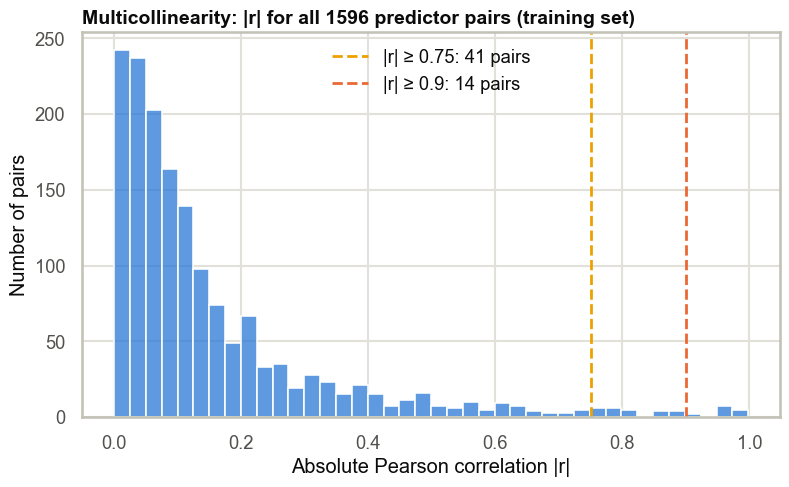

In [10]:
pairs = pp.correlated_pairs(X_train, threshold=0.90)
print(f"{len(pairs)} predictor pairs have |r| >= 0.90 in the training set")
display(pairs)
show(viz.plot_pairwise_correlation_hist(X_train))

Fourteen pairs have |r| ≥ 0.90. Some are nearly duplicates (MP25/MP26/MP27 all have r ≈ 0.99).
This **multicollinearity** makes OLS coefficients unstable: the model cannot tell which of two
almost-identical columns deserves the credit, so small data changes can swing their coefficients
in opposite directions. Regularisation and PCA are designed for exactly this situation.

## 3. Batch dependency check

The 12 biological-material measurements describe the raw material that went into a batch.
If two rows have *identical* values for all 12, they very likely used the same raw-material lot.

In [11]:
groups = dl.batch_groups(df)
sizes = groups.value_counts()
print("Distinct biological-material profiles:", groups.nunique())
print("Profiles by number of batches sharing them:", sizes.value_counts().sort_index().to_dict())

within_sd = df.groupby(groups)[dl.TARGET].std().dropna()
print(f"Mean within-profile SD of yield: {within_sd.mean():.2f}  vs overall SD: {y_all.std():.2f}")

shared = set(groups[X_train.index]) & set(groups[X_test.index])
overlap = groups[X_test.index].isin(shared).sum()
print(f"Test batches whose raw-material profile also occurs in training: {overlap} of {len(X_test)}")

Distinct biological-material profiles: 108
Profiles by number of batches sharing them: {1: 73, 2: 2, 3: 33}
Mean within-profile SD of yield: 0.49  vs overall SD: 1.85
Test batches whose raw-material profile also occurs in training: 18 of 36


**Finding.** There are only **108 distinct raw-material profiles for 176 batches**. 33 profiles
appear three times and 2 appear twice, so 103 batches share raw material with another batch.
Yields inside a shared profile are much more alike (within-profile SD ≈ 0.49) than yields overall
(SD ≈ 1.85).

With a purely random split, **18 of the 36 test batches have a "sibling" batch in the training set**.
A model can partly recognise the raw-material lot instead of learning a general relationship, so
**random train/test evaluation may be optimistic**. We keep the random split required by the
project specification as the primary analysis, and in Section 7 we add a sensitivity analysis that
groups batches by raw-material profile.

## 4. Preprocessing and leakage control

Every model is a scikit-learn **Pipeline**:

1. `NearZeroVarianceFilter` – drops near-constant columns (Kuhn & Johnson rule: most common value
   > 19× as frequent as the second *and* < 10 % distinct values);
2. `SimpleImputer(strategy="median")` – fills missing values with the *training* median;
3. `StandardScaler` – rescales each column to mean 0, SD 1;
4. the model (optionally preceded by `PCA`).

Because these steps sit inside the pipeline, `GridSearchCV` refits them **inside each CV fold**,
using only that fold's training part. Medians, means, SDs and principal components are never computed
from validation or test rows. This prevents **data leakage**. Model selection uses 5-fold CV with
`shuffle=True, random_state=42` on the 140 training batches only.

In [12]:
specs = tm.model_specs()
for name, (pipe, grid) in specs.items():
    print(f"{name:18s} steps={[s for s, _ in pipe.steps]}  tuned={list(grid) or 'nothing'}")
specs["PCR"][0]

Linear Regression  steps=['prep', 'model']  tuned=nothing
Ridge              steps=['prep', 'model']  tuned=['model__alpha']
Lasso              steps=['prep', 'model']  tuned=['model__alpha']
PCR                steps=['prep', 'pca', 'model']  tuned=['pca__n_components']
KNN Regression     steps=['prep', 'model']  tuned=['model__n_neighbors', 'model__weights']


Pipeline(steps=[('prep',
                 Pipeline(steps=[('nzv', NearZeroVarianceFilter()),
                                 ('impute', SimpleImputer(strategy='median')),
                                 ('scale', StandardScaler())])),
                ('pca', PCA()), ('model', LinearRegression())])

## 5. Models

### Model 1 — Multiple linear regression (OLS)

OLS estimates $\hat y = \hat\beta_0 + \sum_j \hat\beta_j x_j$ by minimising the residual sum of squares
$\sum_i (y_i - \hat y_i)^2$. It assumes a linear relationship, independent errors with constant
variance, (approximately) normal errors for inference, and no severe multicollinearity.
Here it estimates 57 parameters from 140 batches, which is about 2.5 observations per parameter.

In [13]:
searches = {}
searches["Linear Regression"] = tm.tune_model(*specs["Linear Regression"], X_train, y_train)
s = searches["Linear Regression"]
fold_rmse = [-s.cv_results_[f"split{i}_test_score"][0] for i in range(5)]
print("Removed by near-zero-variance filter:", s.best_estimator_.named_steps["prep"].named_steps["nzv"].removed_features_)
print("Per-fold CV RMSE:", np.round(fold_rmse, 2))
print(f"Mean CV RMSE = {np.mean(fold_rmse):.3f}   Training RMSE = {-s.cv_results_['mean_train_score'][0]:.3f}")

Removed by near-zero-variance filter: ['BiologicalMaterial07']
Per-fold CV RMSE: [25.84  1.31  2.09  1.57 20.27]
Mean CV RMSE = 10.215   Training RMSE = 0.744


Only `BiologicalMaterial07` (173 of 176 values identical) is removed as near-constant, leaving
56 predictors. OLS fits the training data very closely (training RMSE ≈ 0.81), but **two of the
five CV folds have RMSE above 20**. Those folds contain the extreme batches from Section 2.6; with
56 unpenalised and highly collinear coefficients, the model extrapolates to absurd predictions.
This is textbook **overfitting / high variance**.

In [14]:
full_vif = ev.full_ols_vif(X_train, searches)
print(f"Predictors with VIF > 10: {(full_vif > 10).sum()} of {len(full_vif)}")
full_vif.head(10).to_frame()

Predictors with VIF > 10: 36 of 56


,VIF
ManufacturingProcess21,inf
ManufacturingProcess17,inf
ManufacturingProcess13,inf
ManufacturingProcess25,6055.765
ManufacturingProcess26,5468.508
ManufacturingProcess27,2816.966
ManufacturingProcess20,1544.143
ManufacturingProcess18,1532.295
ManufacturingProcess29,430.071
BiologicalMaterial06,189.025


A **variance inflation factor (VIF)** above 10 is a common warning sign; here many predictors exceed
it, and some are infinite (an exact linear combination of other columns). The coefficients of the full OLS model
therefore **cannot be interpreted individually**.

**Interpretable OLS on a justified subset.** To still get a readable statistical summary, we fit
statsmodels OLS on 8 predictors chosen *from the training set only*: rank predictors by |r| with
yield, and add one only if its |r| with every already-chosen predictor is ≤ 0.70. This keeps the
subset free of strong collinearity (all VIFs below are small). Predictors are standardised, so each
coefficient is the change in yield (percentage points) for a one-SD increase, holding the
others fixed.

In [15]:
subset = pp.select_uncorrelated_top_features(X_train, y_train, k=8, max_inter_corr=0.70)
ols_fit, ols_vif = ev.ols_statsmodels(X_train, y_train, subset)
print(ols_fit.summary())
display(ols_vif.round(2).to_frame())

                            OLS Regression Results                            
Dep. Variable:                  Yield   R-squared:                       0.616
Model:                            OLS   Adj. R-squared:                  0.592
Method:                 Least Squares   F-statistic:                     26.24
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           7.60e-24
Time:                        18:13:09   Log-Likelihood:                -221.05
No. Observations:                 140   AIC:                             460.1
Df Residuals:                     131   BIC:                             486.6
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                     40

,VIF
ManufacturingProcess32,2.05
BiologicalMaterial06,2.57
ManufacturingProcess13,2.71
BiologicalMaterial08,2.39
BiologicalMaterial04,2.67
ManufacturingProcess06,1.29
ManufacturingProcess11,1.99
ManufacturingProcess12,1.62


The subset model explains about 62 % of training variance (adjusted R² ≈ 0.59). Every VIF is below 3,
so these coefficients are stable. `ManufacturingProcess32` has the strongest positive association
(+0.94 per SD) and `ManufacturingProcess13` a negative one (−0.55 per SD). BM06 and MP11 are also
significant at the 5 % level. *Caveat:* the 8 variables were chosen using the same data, so the
p-values are optimistic (selection bias) and should be read as descriptive.

**Residual diagnostics** for the full OLS model (training data):

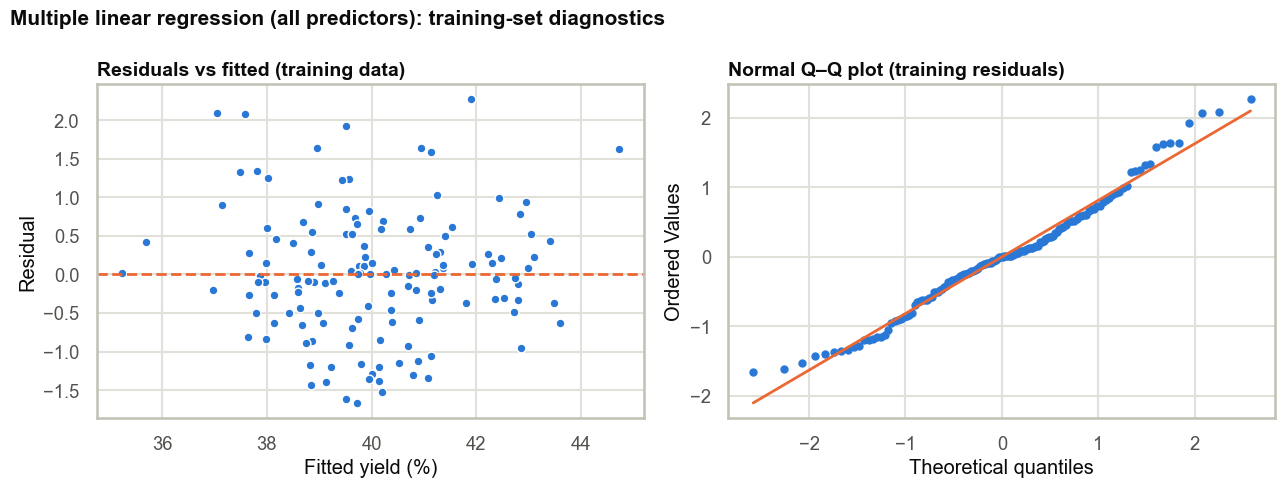

In [16]:
show(viz.plot_ols_diagnostics(s, X_train, y_train))

The training residuals look roughly random with roughly normal tails. That is expected: a model with 57
parameters can fit 140 points well. The problem with OLS is not the training fit but its
**instability on new data**, which the CV folds expose.

### Model 2 — Ridge regression (L2 penalty)

Ridge minimises $\text{RSS} + \alpha\sum_j \beta_j^2$. The penalty shrinks all coefficients toward
zero. Correlated predictors then share credit instead of receiving huge opposite-signed
coefficients. Larger $\alpha$ gives a simpler, lower-variance (but more biased) model.
$\alpha$ is chosen by 5-fold CV over 61 values from $10^{-2}$ to $10^{4}$.

In [17]:
searches["Ridge"] = tm.tune_model(*specs["Ridge"], X_train, y_train)
print("Best alpha:", round(searches["Ridge"].best_params_["model__alpha"], 2),
      "  CV RMSE:", round(-searches["Ridge"].best_score_, 3))

Best alpha: 125.89   CV RMSE: 1.582


### Model 3 — Lasso regression (L1 penalty)

Lasso minimises $\text{RSS} + \alpha\sum_j |\beta_j|$ (scikit-learn scales the RSS by $1/2n$).
Unlike Ridge, the L1 penalty can set coefficients **exactly to zero**, so Lasso also performs
**feature selection**. With groups of correlated predictors, Lasso tends to keep one representative
and drop the rest, whereas Ridge spreads the weight across all of them.

In [18]:
searches["Lasso"] = tm.tune_model(*specs["Lasso"], X_train, y_train)
lasso_coef = ev.linear_coefficients(searches["Lasso"])
print("Best alpha:", round(searches["Lasso"].best_params_["model__alpha"], 4),
      "  CV RMSE:", round(-searches["Lasso"].best_score_, 3))
print(f"Non-zero coefficients: {(lasso_coef != 0).sum()} of {len(lasso_coef)}")
print("Set to zero:", ", ".join(sorted(lasso_coef.index[lasso_coef == 0]
                                     .str.replace("ManufacturingProcess", "MP")
                                     .str.replace("BiologicalMaterial", "BM"))))
lasso_coef[lasso_coef != 0].sort_values(key=abs, ascending=False).round(3).to_frame("Lasso coefficient")

Best alpha: 0.0708   CV RMSE: 1.195
Non-zero coefficients: 22 of 56
Set to zero: BM01, BM02, BM03, BM04, BM08, BM09, BM10, BM11, BM12, MP01, MP02, MP03, MP05, MP08, MP10, MP11, MP12, MP14, MP16, MP18, MP19, MP20, MP21, MP22, MP25, MP26, MP27, MP29, MP30, MP31, MP33, MP38, MP41, MP42


,Lasso coefficient
ManufacturingProcess32,0.761
ManufacturingProcess09,0.553
ManufacturingProcess17,-0.304
BiologicalMaterial06,0.270
ManufacturingProcess37,-0.172
ManufacturingProcess39,0.143
BiologicalMaterial05,0.127
ManufacturingProcess06,0.123
ManufacturingProcess36,-0.101
ManufacturingProcess34,0.094


Lasso keeps **22 of 56 predictors** and sets 34 exactly to zero. The model is much
simpler to explain. Among the near-duplicate groups (MP25–MP31, MP18/MP20, BM02/BM06) it
keeps at most one member. The largest standardised coefficients belong to `ManufacturingProcess32` (+0.76),
`ManufacturingProcess09` (+0.55), `ManufacturingProcess17` (−0.30) and `BiologicalMaterial06` (+0.27).

### Model 4 — Principal component regression (PCR)

PCR first replaces the 56 standardised predictors with $M$ uncorrelated **principal components**
(linear combinations that capture the most variance), then fits OLS on those $M$ components.
This removes multicollinearity by construction and reduces the number of parameters. PCA does
**not** look at yield when building components, so high-variance directions are not guaranteed
to be the most predictive. $M$ is chosen by 5-fold CV over 1–40.

Selected components: 22  CV RMSE: 1.352
Variance explained by 22 PCs: 92.9%; first PC alone: 17.9%


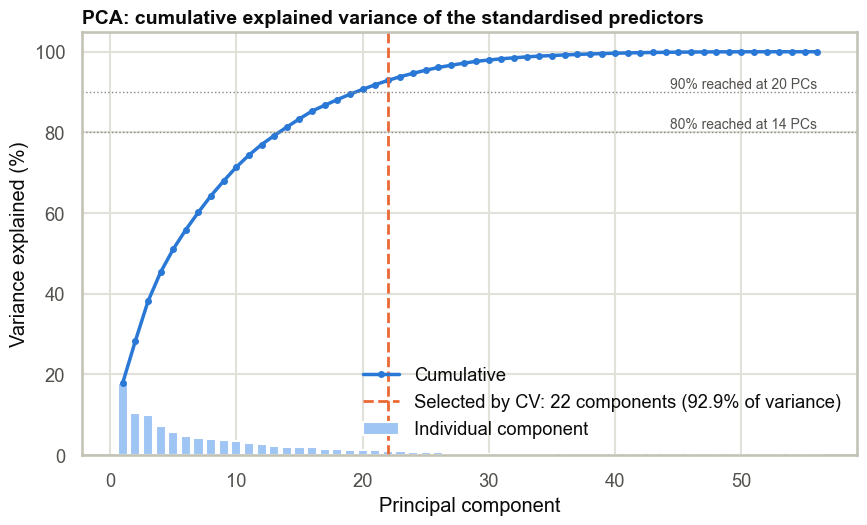

In [19]:
searches["PCR"] = tm.tune_model(*specs["PCR"], X_train, y_train)
k = searches["PCR"].best_params_["pca__n_components"]
evr = viz.pca_explained_variance(searches["PCR"], X_train)
print(f"Selected components: {k}  CV RMSE: {-searches['PCR'].best_score_:.3f}")
print(f"Variance explained by {k} PCs: {evr[:k].sum():.1%}; first PC alone: {evr[0]:.1%}")
show(viz.plot_pca_variance(searches["PCR"], X_train))

The first component explains only about 18 % of the variance, so the information is spread over many
directions. CV selects **22 components (≈ 93 % of the variance)**: PCR cuts 56 correlated inputs
to 22 uncorrelated ones. With too few components the model underfits (CV RMSE ≈ 2 at 1–10 PCs);
with too many it reintroduces the extreme-value instability of OLS (CV RMSE rises sharply beyond
~27 PCs).

### Model 5 — K-nearest-neighbours regression

KNN predicts a batch's yield as the (optionally distance-weighted) average yield of the $k$ most
similar training batches in standardised feature space. It is **non-parametric**: it assumes no
functional form. Small $k$ means low bias and high variance (it follows individual neighbours);
large $k$ means smoother predictions with higher bias. With 56 dimensions and 140 points, the "nearest"
neighbours are not very near (the *curse of dimensionality*), which limits KNN here.

Best: {'model__n_neighbors': 12, 'model__weights': 'distance'}   CV RMSE: 1.327


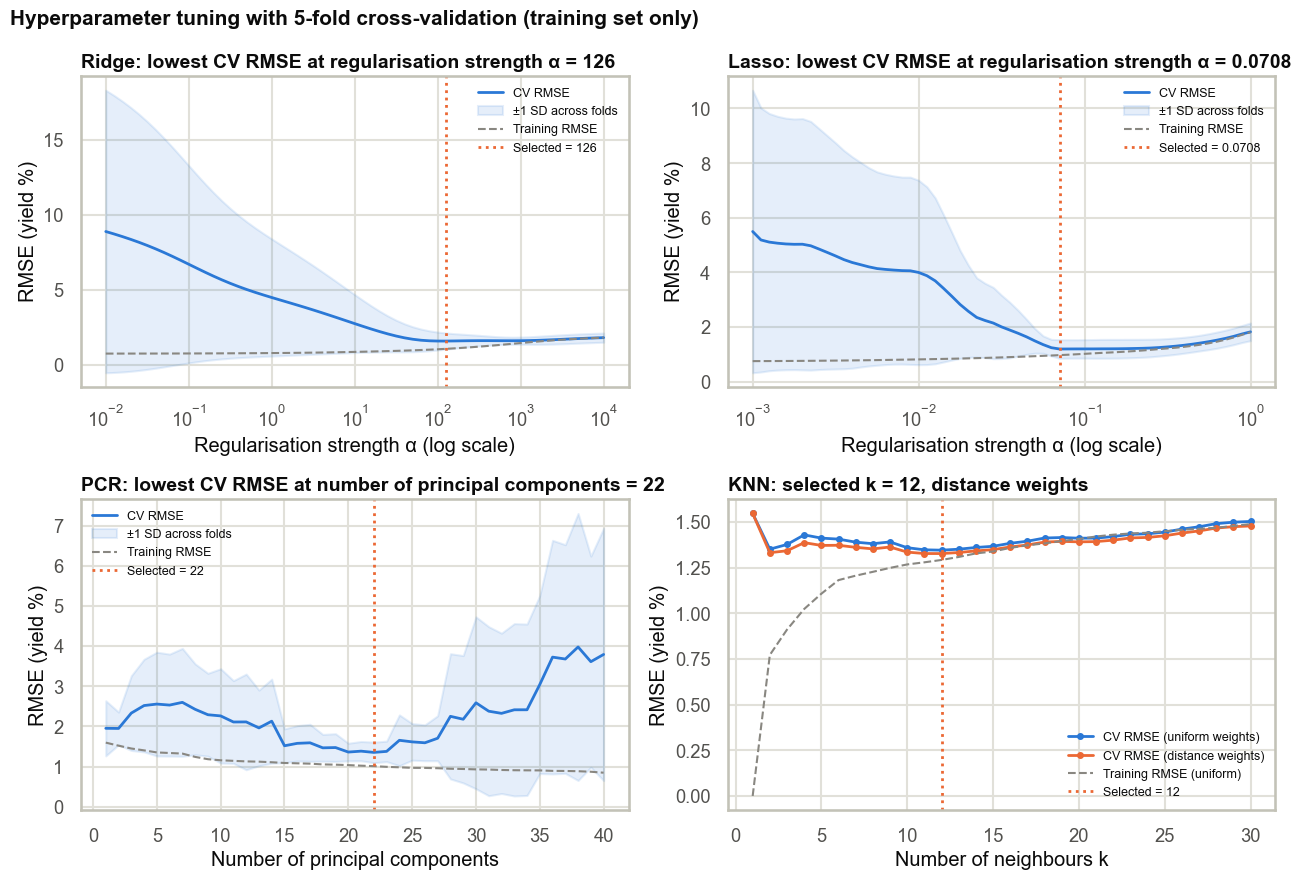

In [20]:
searches["KNN Regression"] = tm.tune_model(*specs["KNN Regression"], X_train, y_train)
print("Best:", searches["KNN Regression"].best_params_,
      "  CV RMSE:", round(-searches["KNN Regression"].best_score_, 3))
searches = {m: searches[m] for m in tm.MODEL_ORDER}
show(viz.plot_cv_curves(searches))

**Validation curves (bias–variance trade-off in action).** In every panel the training RMSE (dashed)
keeps falling as the model becomes more flexible (smaller $\alpha$, more components, smaller $k$),
while CV RMSE is U-shaped. On the left side the model is too flexible and *overfits*: training error
is low and CV error high and highly variable across folds. On the right side it is too rigid and
*underfits*. The selected values (dotted lines) sit at the bottom of the U. For KNN with k = 1 the
training RMSE is 0, because each point is its own nearest neighbour, which is perfect memorisation.

## 6. Model evaluation and comparison

Models were **selected by CV RMSE on the training set**. Only now is each tuned model, refitted on all
140 training batches, applied to the **36 untouched test batches**.

In [21]:
results = ev.comparison_table(searches, X_train, y_train, X_test, y_test)
best = tm.select_best_model(searches)
print("Selected model (lowest CV RMSE):", best)
results[["CV RMSE", "Test MSE", "Test RMSE", "Test MAE", "Test R²", "Selected hyperparameters"]]

Selected model (lowest CV RMSE): Lasso


,CV RMSE,Test MSE,Test RMSE,Test MAE,Test R²,Selected hyperparameters
Model,,,,,,
Linear Regression,10.215,2.073,1.440,1.109,0.126,none
Ridge,1.582,1.544,1.243,1.023,0.349,alpha=125.9
Lasso,1.195,1.187,1.089,0.859,0.500,alpha=0.07079
PCR,1.352,1.664,1.290,1.022,0.298,n_components=22
KNN Regression,1.327,1.722,1.312,1.130,0.274,"n_neighbors=12, weights=distance"


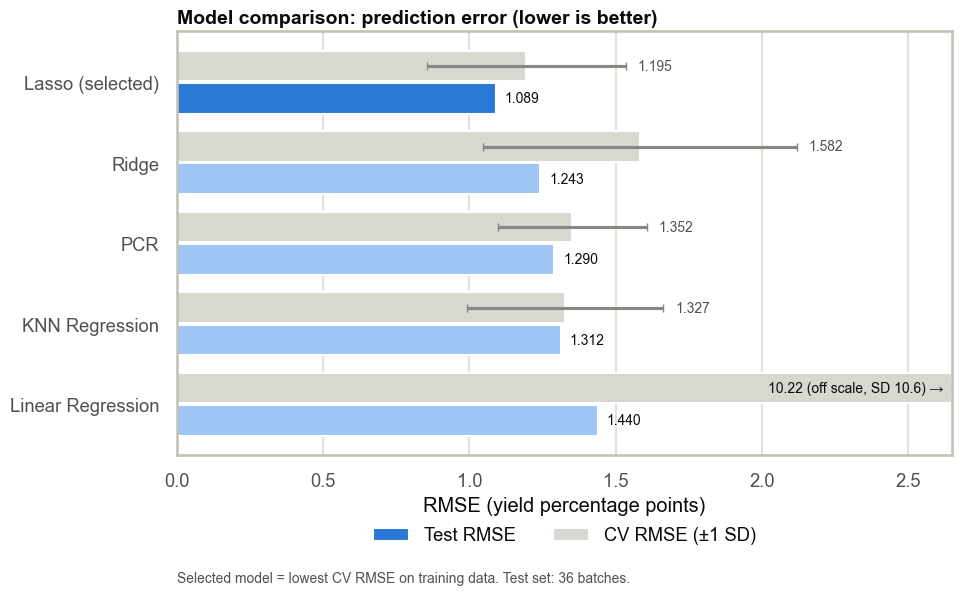

In [22]:
show(viz.plot_model_comparison(results, best, n_test=len(y_test)))

**Lasso is best on every metric.** It has the lowest CV RMSE (1.20, which is how it was chosen) and the
lowest test MSE, RMSE (1.09), MAE (0.86) and the highest test R² (0.50). It explains about half of the
batch-to-batch yield variation on unseen batches. Its typical error is about 1.1 percentage points,
compared with the yield SD of 1.85. Lasso ranks first under both CV and the test set and OLS ranks last under both. The order of the
middle three changes (CV: KNN < PCR < Ridge; test: Ridge < PCR < KNN), and with only 36 test batches
their differences (1.24–1.31) are within noise.

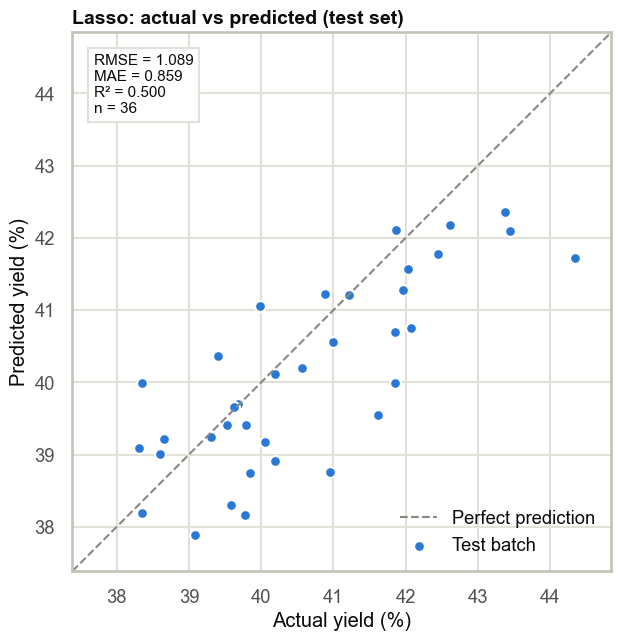

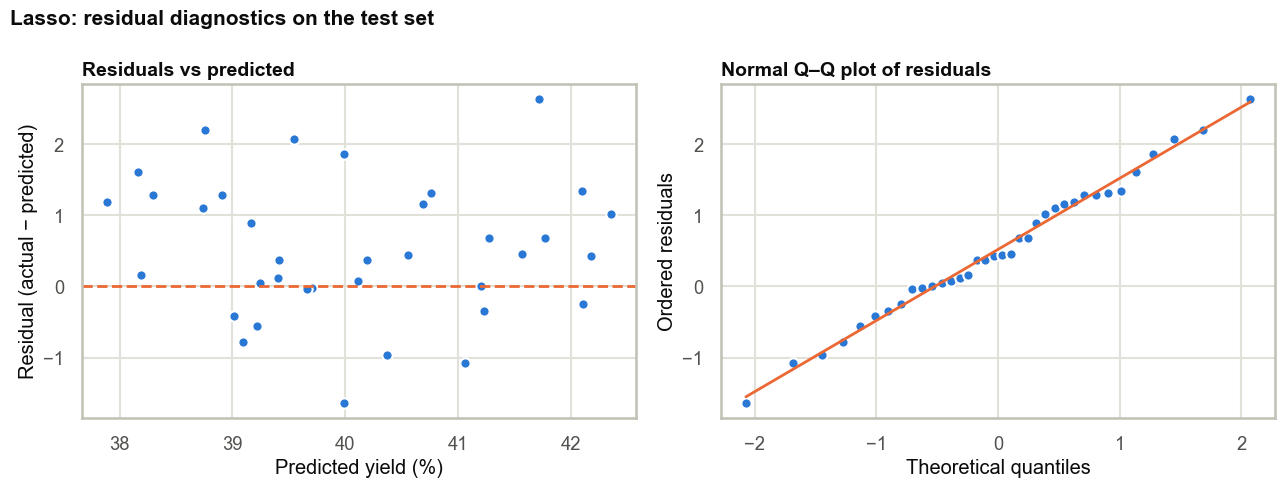

In [23]:
pred = searches[best].predict(X_test)
show(viz.plot_actual_vs_predicted(y_test, pred, best, ev.regression_metrics(y_test, pred)))
show(viz.plot_residuals(y_test, pred, best))

**Actual vs predicted.** Points follow the diagonal, so the model ranks batches sensibly. The cloud is
flatter than the diagonal, though: high-yield batches are under-predicted and low-yield batches
over-predicted. This *shrinkage toward the mean* is typical of a regularised model with moderate R².

**Residuals.** There is no funnel shape, so the variance looks roughly constant, and the Q–Q plot
is close to a straight line, so the residuals are approximately normal. The residuals are, however,
**shifted upward**: the mean residual is about +0.5 and 26 of 36 are positive. The model
systematically under-predicts this test set. This matches the split itself: the test batches have a
higher average yield (40.62) than the training batches (40.06), and a shrunken model pulls predictions
toward the training mean. Much of the test RMSE therefore comes from this offset rather than from scatter.

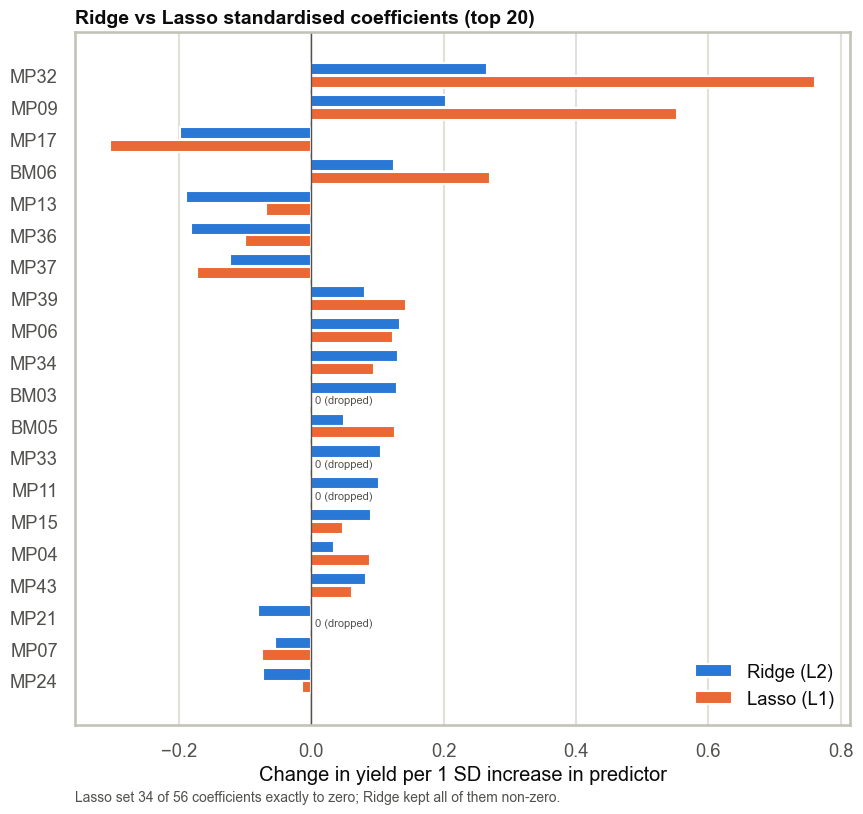

,OLS,Ridge,Lasso,PCR
ManufacturingProcess32,1.455,0.266,0.761,0.294
ManufacturingProcess09,0.459,0.204,0.553,0.145
ManufacturingProcess17,-0.218,-0.198,-0.304,-0.285
ManufacturingProcess13,-0.147,-0.189,-0.068,-0.270
ManufacturingProcess36,0.298,-0.182,-0.101,-0.308
ManufacturingProcess06,0.155,0.135,0.123,0.288
ManufacturingProcess34,-0.028,0.131,0.094,0.275
BiologicalMaterial03,0.604,0.130,0.000,0.097
BiologicalMaterial06,0.453,0.125,0.270,0.088
ManufacturingProcess37,-0.199,-0.123,-0.172,-0.133


In [24]:
coefs = ev.coefficient_table(searches)
show(viz.plot_ridge_vs_lasso(coefs, n=20))
coefs.head(12).round(3)

**Ridge vs Lasso coefficients.** Both methods agree on the direction of the main associations:
MP32, MP09, BM06 and MP39 are positive; MP17, MP13, MP36 and MP37 are negative. Ridge spreads weight
over correlated groups. For example, it keeps MP33 (r = 0.86 with MP32) and BM03, which Lasso drops.
Lasso concentrates weight on fewer variables, so its retained coefficients are larger. The OLS
coefficients (in the table) reach magnitudes above 6 because of collinearity, which is far larger than any
plausible effect.

In [25]:
ev.overfitting_table(results).round(3)

,Train RMSE,CV RMSE,Test RMSE,CV / Train ratio
Model,,,,
Linear Regression,0.810,10.215,1.440,12.619
Ridge,1.068,1.582,1.243,1.482
Lasso,1.010,1.195,1.089,1.183
PCR,1.042,1.352,1.290,1.298
KNN Regression,0.000,1.327,1.312,NaN


**Overfitting check.** A model that generalises well has CV/test error close to its training error.
OLS shows the clearest overfitting: training RMSE 0.81, CV RMSE 10.2. KNN with distance
weighting has training RMSE 0 (each training point predicts itself, so the ratio is undefined), which is why the CV
estimate rather than training error is used for selection. Ridge, Lasso and PCR show moderate gaps
(training ≈ 1.0, CV 1.2–1.6), as expected after regularisation.

## 7. Sensitivity analyses
### 7.1 Batch-grouped validation

We re-score each selected model with **GroupKFold**, where every raw-material profile is kept entirely
inside one fold. We then repeat the *whole* analysis with a **group-wise 80/20 split**
(`GroupShuffleSplit`), tuning by GroupKFold.

In [26]:
grouped_cv = tm.grouped_cv_comparison(searches, X_train, y_train, groups[X_train.index])
grouped_cv

,Random 5-fold CV RMSE,Grouped 5-fold CV RMSE,Increase (%)
Model,,,
Linear Regression,10.215,13.509,32.241
Ridge,1.582,1.561,-1.372
Lasso,1.195,1.320,10.480
PCR,1.352,1.490,10.224
KNN Regression,1.327,1.394,4.988


Grouped split: 146 training / 30 test batches


,Grouped CV RMSE,Grouped test RMSE,Grouped test R²
Model,,,
Linear Regression,4.745,0.971,0.704
Ridge,1.416,1.088,0.629
Lasso,1.272,0.936,0.725
PCR,1.584,1.304,0.466
KNN Regression,1.394,1.494,0.299


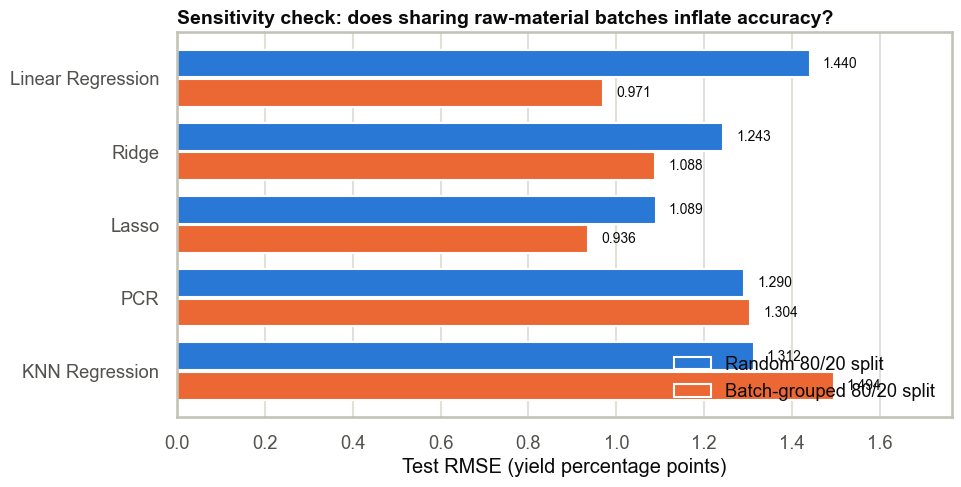

In [27]:
grouped_hold = tm.grouped_holdout_evaluation(X, y, groups)
print(f"Grouped split: {grouped_hold.attrs['n_train']} training / {grouped_hold.attrs['n_test']} test batches")
display(grouped_hold)
show(viz.plot_grouped_validation(results, grouped_hold))

**Interpretation.** On the same training data, grouped CV RMSE is **about 10 % higher** for Lasso
and PCR, 5 % higher for KNN and 32 % higher for OLS, while Ridge is essentially unchanged (−1 %).
Part of the random-CV accuracy therefore comes from recognising batches that share raw material,
which confirms the dependency found in Section 3. **Lasso remains the best model under grouped CV**
(1.32).

The grouped *hold-out* (146 training / 30 test batches, split by raw-material profile) again puts
Lasso first (test RMSE 0.94, R² 0.73). Its test RMSEs happen to be *lower* than the random-split
ones. That is not a contradiction: the grouped split uses a different, smaller set of test batches
that turns out easier to predict. Even OLS does well there (0.97) because none of the extreme
batches landed in that test set. This shows how much a single small test set varies (next section).
The like-for-like comparison is grouped vs random CV on identical data, where grouping makes the task harder.

### 7.2 Repeated random splits

To see how much the conclusions depend on the particular split, we repeat the full procedure
(split → tune by 5-fold CV → test) for 20 different random seeds.

,mean,median,std,min,max,times best
Model,,,,,,
Linear Regression,4.665,1.417,8.042,0.968,28.168,2
Ridge,1.555,1.364,0.598,1.032,3.343,1
Lasso,1.281,1.230,0.349,0.973,2.649,9
PCR,1.435,1.305,0.415,1.033,2.643,3
KNN Regression,1.346,1.310,0.223,0.974,1.733,5


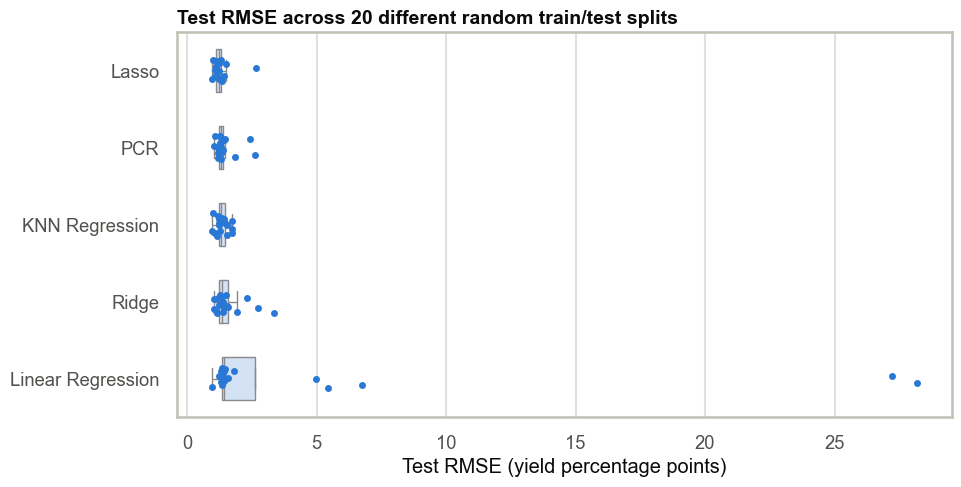

In [28]:
repeated = tm.repeated_split_evaluation(X, y, n_repeats=20)
rep = repeated.groupby("Model")["Test RMSE"].agg(["mean", "median", "std", "min", "max"]).reindex(tm.MODEL_ORDER)
rep["times best"] = (repeated.loc[repeated.groupby("seed")["Test RMSE"].idxmin(), "Model"]
                     .value_counts().reindex(tm.MODEL_ORDER, fill_value=0))
display(rep)
show(viz.plot_repeated_splits(repeated))

Across 20 splits, **Lasso has the lowest average test RMSE (≈ 1.28)** and is the best model most often
(9 of 20 splits). KNN is the most *stable* (smallest spread) but slightly less accurate on average.
OLS is erratic, with test RMSE up to 28 when extreme batches land in the test set. Test RMSE for any one
model varies by roughly ±0.3 across splits, which is as large as the gaps between Lasso, KNN, PCR and Ridge.
**Model differences other than "OLS is clearly worst" should therefore be stated cautiously.**

## 8. Findings, conclusions and limitations

| Question | Evidence-based answer |
|---|---|
| Lowest prediction error? | **Lasso**: test RMSE 1.09, MAE 0.86, R² 0.50; also lowest CV RMSE (1.20) and lowest mean RMSE over 20 splits. |
| Did regularisation help? | **Yes, decisively.** OLS CV RMSE 10.2 → Ridge 1.58 → Lasso 1.20. Test RMSE fell from 1.44 (OLS) to 1.24 (Ridge) and 1.09 (Lasso). |
| Did PCA reduce dimensionality without losing much accuracy? | Partly. 56 → 22 components kept ~93 % of variance and greatly improved on OLS (test RMSE 1.29), but PCR was less accurate than Lasso because PCA ignores the target. |
| Features most associated with yield? | Consistently across Lasso, Ridge and the subset OLS: **MP32 (+), MP09 (+), BM06 (+), MP13 (−), MP17 (−), MP36/MP37 (−)**. These are associations only. |
| Evidence of overfitting? | Yes for OLS (train 0.81 vs CV 10.2) and for KNN with small k. Regularised models show modest gaps. |
| Why Lasso? | Best accuracy *and* the simplest model (22 of 56 predictors, linear and readable coefficients). It handles collinearity by selecting one variable per correlated group. |

**Conclusion.** Historical process and raw-material measurements can predict batch yield with
moderate accuracy (R² ≈ 0.5, RMSE ≈ 1.1 points against a natural SD of 1.85). Controlling model
complexity is essential with 57 correlated predictors and 140 training batches. **The Lasso offers
the best balance of accuracy, complexity and interpretability**, which supports our hypothesis.

**Limitations**
* **Small sample.** 176 batches; the 36-batch test set gives noisy estimates (±0.3 RMSE across splits).
* **Non-independent batches.** 103 batches share raw-material profiles; random splitting overstates accuracy by ~5–10 % in CV RMSE.
* **Multicollinearity.** Individual coefficients are unstable; Lasso's choice between near-duplicate variables is somewhat arbitrary.
* **Missing values and suspected zero-codes.** Median imputation ignores the uncertainty of the imputed values; possible placeholder zeros were left unchanged.
* **Selection bias in the OLS subset** p-values.
* **Observational data.** The associations are not causal and do not justify changing process settings.
* Only linear models and KNN were compared, as required by the project scope.

**References**
1. Kuhn, M. & Johnson, K. (2013). *Applied Predictive Modeling*. Springer. (Dataset source; Ch. 6 & 12 exercises.)
2. Kuhn, M. & Johnson, K. (2018). *AppliedPredictiveModeling: Functions and Data Sets for 'Applied Predictive Modeling'*. R package v1.1-7, CRAN.
3. James, G., Witten, D., Hastie, T. & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2nd ed.). Springer. Ch. 2, 3, 5, 6.
4. Hastie, T., Tibshirani, R. & Friedman, J. (2009). *The Elements of Statistical Learning* (2nd ed.). Springer.
5. Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. *JRSS-B*, 58(1), 267–288.
6. Hoerl, A. & Kennard, R. (1970). Ridge regression: biased estimation for nonorthogonal problems. *Technometrics*, 12(1), 55–67.
7. Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *JMLR*, 12, 2825–2830.